# 02 · Backtester: does industry momentum survive costs, publication and crashes?

**The strategy.** Each month, buy the industries with the best returns over the past year and short the worst. Moskowitz and Grinblatt (*Do Industries Explain Momentum?*, Journal of Finance 1999) found this earned large returns in 1963–95, and argued that much of the famous stock-level momentum effect is really industry momentum.

**Why it is a good test case.** A backtest that looks good on paper can fail in practice in four standard ways, and this study checks each one:

1. **Is it something new, or a known factor in disguise?** Regress it on the Fama-French factors and stock momentum.
2. **Did it survive publication?** McLean and Pontiff (2016) find anomaly returns fall by about half after the paper appears.
3. **Does it survive trading costs?** Momentum trades a lot.
4. **What are the tail risks?** Daniel and Moskowitz (2016) show momentum crashes when markets rebound after a bear market.

Plus a fifth that applies to every backtest: **was the design chosen after seeing the results?** I fixed the headline design before running it, then ran 96 variants and corrected for having tried them all (the deflated Sharpe ratio).

**Data.** Kenneth French's 49 value-weighted industry portfolios, monthly from July 1926. Industries don't go bankrupt or get delisted, so unlike a stock universe chosen today, this one has **no survivorship bias**.

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from quant_research.backtest import engine, metrics as mt
from quant_research.data import french, prices
from quant_research.factors import model, portfolios as pf
from quant_research.strategies import momentum as mom

pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 110})
pct = plt.FuncFormatter(lambda x, _: f"{x:.0%}")

ind = french.load("ind49")
ff3 = french.load("ff3")            # market factor back to 1926
f = french.factors()                # FF5 + momentum, from 1963
print(f"{ind.shape[1]} industries, {ind.index.min():%Y-%m} to {ind.index.max():%Y-%m}; "
      f"industries with data in July 1926: {ind.iloc[0].notna().sum()}, all 49 from {ind.notna().all(axis=1).idxmax():%Y-%m}")

49 industries, 1926-07 to 2026-09; industries with data in July 1926: 40, all 49 from 1969-07


## The backtester

`quant_research.backtest.engine.run(weights, returns, cost_bps, borrow_bps)` takes a table of target weights and returns monthly gross and net returns. Three rules keep it honest (each is covered by a test):

- **Timing.** Weights dated month *t* are traded at *t*'s close and earn returns from month *t + 1*. A signal can never see the return it is trying to predict.
- **Drift.** Between trades, positions move with their own returns. Turnover is measured against these drifted weights, so a strategy pays to restore its targets even when its picks don't change.
- **Costs.** Trading cost = cost in bps × one-way turnover. Borrow cost is charged annually on the short side.

**One data gap.** The Rubber industry has no firms from July 1943 to June 1944. French rebuilds the portfolios each June, so an empty industry is known at that point. A position held into the gap is treated as sold at the June close (0% return); the signal skips Rubber until it has a full year of data again.

In [2]:
gaps = {c: int(ind[c][ind[c].first_valid_index():].isna().sum()) for c in ind}
print({c: n for c, n in gaps.items() if n})
tradable = ind.where(ind.notna() | ind.ffill().isna(), 0.0)    # internal gaps -> cash

{'Rubbr': 12}


## The headline strategy

Fixed before looking at results, following the standard momentum convention:
- **Signal:** each industry's return over the past 12 months, **skipping the most recent month** (very short-term returns tend to reverse, which would contaminate the signal).
- **Portfolio:** long the top 20% of industries (about 10), short the bottom 20%, equal weights, rebalanced monthly.

In [3]:
w = mom.long_short(mom.trailing_return(ind, lookback=12, skip=1), fraction=0.2)
w = w[w.index < ind.index.max()]
bt = engine.run(w, tradable)
gross = bt.gross
lo, hi = mt.bootstrap_sharpe(gross)
head = mt.summary(gross)
print(f"Sharpe {head['Sharpe']:.2f}, 95% block-bootstrap interval {lo:.2f} to {hi:.2f}")
head.to_frame("industry momentum (gross)")

Sharpe 0.45, 95% block-bootstrap interval 0.22 to 0.71


,industry momentum (gross)
start,1927-07
end,2026-09
months,1191
return / yr,0.078
volatility,0.172
Sharpe,0.455
t (mean),4.532
max drawdown,-0.849
worst month,-0.580
skew,-2.531


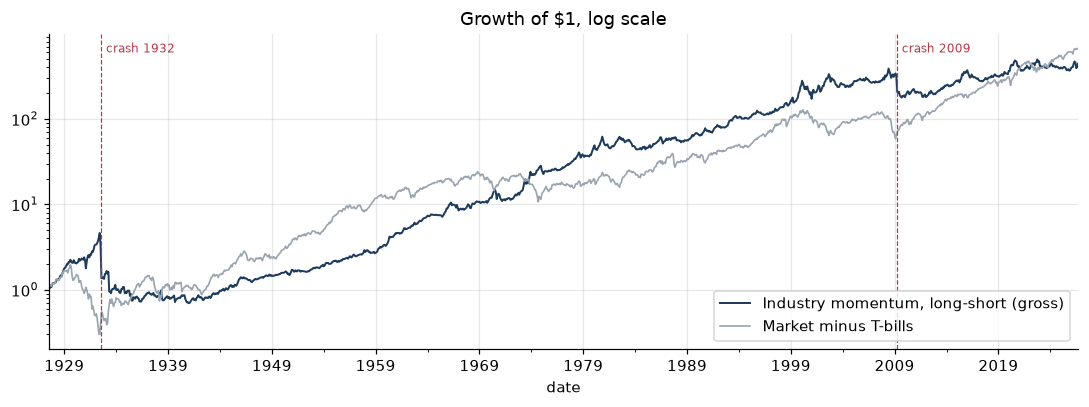

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.8))
(1 + gross).cumprod().plot(ax=ax, logy=True, color="#1f3b5c", lw=1.3, label="Industry momentum, long-short (gross)")
(1 + ff3["Mkt-RF"].loc[gross.index]).cumprod().plot(ax=ax, logy=True, color="#9aa5b1", lw=1.1, label="Market minus T-bills")
for d, label in (("1932-08-31", "1932"), ("2009-04-30", "2009")):
    ax.axvline(pd.Timestamp(d), color="#b23a48", lw=0.8, ls="--")
    ax.annotate(f"crash {label}", (pd.Timestamp(d), ax.get_ylim()[1]), xytext=(3, -12), textcoords="offset points",
                fontsize=8, color="#b23a48")
ax.set_title("Growth of $1, log scale")
ax.legend(loc="lower right")
plt.tight_layout()

Over 99 years the strategy earned about 8% a year at a Sharpe ratio of 0.46 (t ≈ 4.5), comparable to the stock market's own Sharpe ratio, from a portfolio with almost no market exposure. The block bootstrap (12-month blocks, so volatile periods stay together) puts the Sharpe between roughly 0.2 and 0.7.

The rest of the summary matters as much: a maximum drawdown of 85%, a worst month of −58%, strongly negative skew and very fat tails. **The return comes with crash risk**, covered in section 4.

## 1 · Is it just stock momentum?

From 1963, when the five-factor data starts, regress the strategy's return on the factors. Its returns are already long minus short, so no risk-free rate is subtracted.

In [5]:
fits = {"FF3": model.fit(gross, f, ["Mkt-RF", "SMB", "HML"]), "FF5 + Mom": model.fit(gross, f)}
display(pd.DataFrame({k: {"alpha / yr": r.alpha_annual, "t(alpha)": r.alpha_t, "R²": r.r2, "months": r.n}
                      for k, r in fits.items()}).T)
fits["FF5 + Mom"].summary()

,alpha / yr,t(alpha),R²,months
FF3,0.101,5.310,0.052,759.000
FF5 + Mom,0.017,1.361,0.691,759.000


,factor,coef,se,t,p
const,Alpha,0.017,0.012,1.361,0.174
Mkt-RF,Market,0.049,0.029,1.678,0.093
SMB,Size (small minus big),-0.106,0.053,-1.983,0.047
HML,Value (high minus low B/M),0.010,0.055,0.175,0.861
RMW,Profitability (robust minus weak),-0.114,0.058,-1.985,0.047
CMA,Investment (conservative minus aggressive),-0.001,0.076,-0.016,0.987
Mom,Momentum (up minus down),0.897,0.027,32.657,0.000


- **Against value and size alone (FF3), it is a large, significant anomaly.** About 10% a year, t above 5, which is roughly what Moskowitz and Grinblatt found.
- **Add stock momentum and the alpha mostly goes.** The loading on Mom is about 0.9 with a t-statistic above 30, R² jumps to 0.69, and the remaining alpha is under 2% a year and not significant.

So industry momentum and stock momentum are largely the same trade. Moskowitz and Grinblatt read the overlap as "stock momentum is mostly industry momentum"; the regression can't say which way round it goes, only that a fund already holding a momentum factor gains little by adding this one.

## 2 · Did it survive publication?

The paper's sample was 1963–95. That splits history into three parts: before the sample (out of sample, backwards), the sample itself, and the years since.

,months,return / yr,volatility,Sharpe,t (mean),max drawdown
1927–1962 (before the sample),426,0.074,0.197,0.377,2.249,-0.849
1963–1995 (the paper's sample),396,0.100,0.135,0.745,4.280,-0.291
1996–2026 (after),369,0.059,0.177,0.334,1.850,-0.542


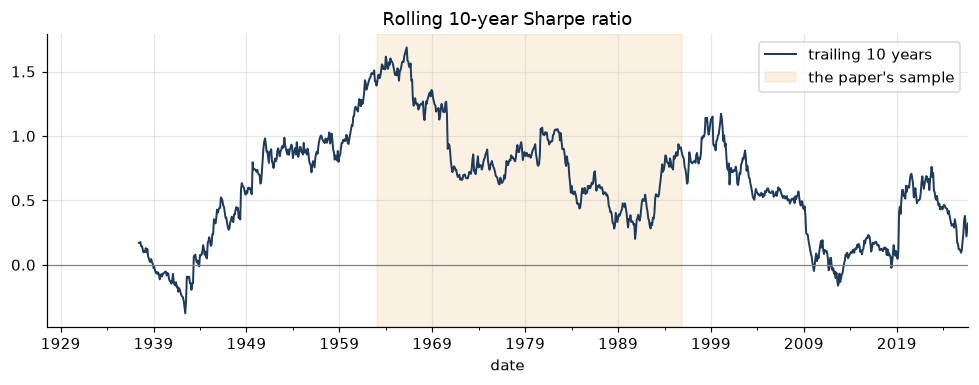

In [6]:
periods = {"1927–1962 (before the sample)": ("1927", "1962"), "1963–1995 (the paper's sample)": ("1963", "1995"),
           "1996–2026 (after)": ("1996", "2026")}
sub = pd.DataFrame({k: mt.summary(gross[a:b]) for k, (a, b) in periods.items()}).T
display(sub[["months", "return / yr", "volatility", "Sharpe", "t (mean)", "max drawdown"]])

roll = gross.rolling(120).apply(lambda x: x.mean() / x.std() * 12 ** 0.5)
ax = roll.plot(color="#1f3b5c", lw=1.3, label="trailing 10 years")
ax.axhline(0, color="grey", lw=0.8)
ax.axvspan(pd.Timestamp("1963-01-01"), pd.Timestamp("1995-12-31"), color="#e8a33d", alpha=0.15, label="the paper's sample")
ax.set_title("Rolling 10-year Sharpe ratio")
ax.legend(loc="upper right")
plt.tight_layout()

The pattern McLean and Pontiff describe: the strategy was strongest in the sample the paper studied (Sharpe 0.75), weaker before it, and weakest after it (a Sharpe of about 0.33, with return down about 40% and only borderline significance). Part of an in-sample result is luck that doesn't repeat, and part is arbitraged away once it is published.

## 3 · Does it survive trading costs?

In [7]:
turnover = bt.returns["turnover"]
be = mt.break_even_cost_bps(gross, turnover)
print(f"Average one-way turnover {turnover.mean():.0%} of capital a month ({turnover.mean() * 12:.1f}x a year); "
      f"break-even cost {be:.0f} bps per trade")
rows = {}
for c in (0, 5, 10, 25, 50):
    n = engine.run(w, tradable, cost_bps=c).net
    rows[f"{c} bps"] = {"net return / yr": n.mean() * 12, "net Sharpe": n.mean() / n.std() * 12 ** 0.5,
                        "net Sharpe since 1996": n["1996":].mean() / n["1996":].std() * 12 ** 0.5}
pd.DataFrame(rows).T

Average one-way turnover 98% of capital a month (11.7x a year); break-even cost 67 bps per trade


,net return / yr,net Sharpe,net Sharpe since 1996
0 bps,0.078,0.455,0.334
5 bps,0.072,0.421,0.299
10 bps,0.067,0.387,0.265
25 bps,0.049,0.284,0.162
50 bps,0.020,0.114,-0.010


The strategy replaces about 100% of capital (one-way) every month, because a 12-month return window changes with every new month. It breaks even at roughly 65 bps per trade.

- **Today**, trading a basket of large-cap stocks or a sector ETF costs a few bps to perhaps 10. At 10 bps the strategy keeps most of its return, though since 1996 that leaves a net Sharpe of about 0.27.
- **Historically** costs were far higher: commissions and spreads of 50 bps or more were normal before the 1980s. The early-sample returns were largely unreachable at the time.

A practical fix would be to trade less: hold each portfolio longer, or only trade when a ranking changes by a margin. Section 5 shows longer holding periods were tested.

## 4 · Momentum crashes

In [8]:
mkt = ff3["Mkt-RF"]
prior = (1 + mkt).rolling(24).apply(np.prod, raw=True).shift(1) - 1
worst = gross.nsmallest(6).to_frame("strategy").join(mkt.rename("market that month")).join(prior.rename("market over prior 2 years"))
worst

,strategy,market that month,market over prior 2 years
date,,,
1932-08-31,-0.580,0.371,-0.684
1933-05-31,-0.413,0.214,-0.379
2009-04-30,-0.350,0.102,-0.434
1932-07-31,-0.295,0.336,-0.754
1938-06-30,-0.200,0.239,-0.285
1931-02-28,-0.198,0.109,-0.427


In [9]:
d = pd.concat([gross.rename("r"), (prior < 0).rename("bear"), mkt.rename("m")], axis=1, join="inner").dropna()
state = np.where(~d["bear"], "Normal (market up over prior 2 years)",
                 np.where(d["m"] > 0, "After a bear market, market rises", "After a bear market, market falls"))
d.groupby(state)["r"].agg(months="count", **{"return / yr": lambda x: x.mean() * 12},
                          volatility=lambda x: x.std() * 12 ** 0.5)

,months,return / yr,volatility
"After a bear market, market falls",119,0.352,0.178
"After a bear market, market rises",156,-0.238,0.300
Normal (market up over prior 2 years),916,0.096,0.130


Every one of the six worst months came **after a bear market, in a month when the market jumped** (for example August 1932, the market +37%; April 2009, +10%). The mechanism (Daniel and Moskowitz 2016): after a crash, the losers are the most beaten-down, highest-risk industries, so the short side is effectively a big bet against the market. When the market snaps back, those industries rebound hardest.

That makes the risk partly predictable. After a bear market the strategy earns very little on average, and its volatility doubles. Risk management here means cutting exposure when the market has fallen over the past two years, not just stop-losses.

## 5 · Was the design chosen after the fact?

I fixed the 12-1, 20%, monthly design before running it. To show how much choice existed, here are 96 variants:
- lookback 3, 6, 9 or 12 months;
- skipping 0 or 1 month;
- holding 1, 3, 6 or 12 months (overlapping portfolios);
- holding the top and bottom 10%, 20% or 30% of industries.

Headline ranks 16 of 96; median variant Sharpe 0.38, best 0.53, worst 0.09


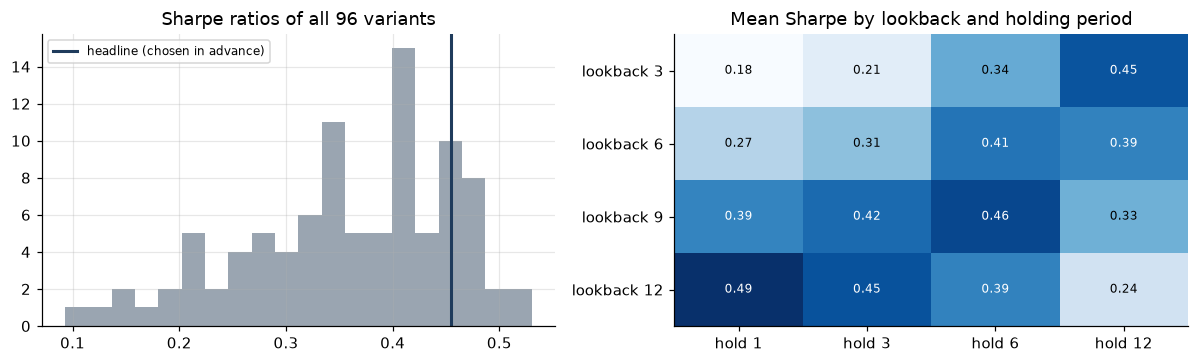

In [10]:
grid = []
for L, S, H, q in itertools.product((3, 6, 9, 12), (0, 1), (1, 3, 6, 12), (0.1, 0.2, 0.3)):
    targets = mom.long_short(mom.trailing_return(ind, L, S), q)
    targets = targets[targets.index < ind.index.max()]
    weights = targets if H == 1 else engine.overlapping(targets, H, ind.index[:-1])
    r = engine.run(weights, tradable).gross
    grid.append({"lookback": L, "skip": S, "holding": H, "fraction": q, "sr_month": r.mean() / r.std()})
grid = pd.DataFrame(grid)
grid["Sharpe"] = grid["sr_month"] * 12 ** 0.5

pivot = grid.groupby(["lookback", "holding"])["Sharpe"].mean().unstack()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(grid["Sharpe"], bins=20, color="#9aa5b1")
axes[0].axvline(head["Sharpe"], color="#1f3b5c", lw=2, label="headline (chosen in advance)")
axes[0].set_title("Sharpe ratios of all 96 variants")
axes[0].legend(fontsize=8)
im = axes[1].imshow(pivot.to_numpy(), cmap="Blues", aspect="auto")
axes[1].set_xticks(range(len(pivot.columns)), [f"hold {h}" for h in pivot.columns])
axes[1].set_yticks(range(len(pivot.index)), [f"lookback {l}" for l in pivot.index])
for (i, j), v in np.ndenumerate(pivot.to_numpy()):
    axes[1].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > pivot.to_numpy().mean() else "black")
axes[1].grid(False)
axes[1].set_title("Mean Sharpe by lookback and holding period")
plt.tight_layout()

rank = int(grid["Sharpe"].rank(ascending=False)[(grid.lookback == 12) & (grid.skip == 1) & (grid.holding == 1)
                                                 & (grid.fraction == 0.2)].iloc[0])
print(f"Headline ranks {rank} of {len(grid)}; median variant Sharpe {grid['Sharpe'].median():.2f}, "
      f"best {grid['Sharpe'].max():.2f}, worst {grid['Sharpe'].min():.2f}")

In [11]:
psr = mt.probabilistic_sharpe(gross)
emax = mt.expected_max_sharpe(grid["sr_month"].to_numpy()) * 12 ** 0.5
dsr = mt.deflated_sharpe(gross, grid["sr_month"].to_numpy())
pd.Series({"Probabilistic Sharpe (P[true Sharpe > 0])": psr,
           "Best Sharpe expected from 96 unskilled variants": emax,
           "Deflated Sharpe (P[beats that bar])": dsr}).to_frame("value")

,value
Probabilistic Sharpe (P[true Sharpe > 0]),1.000
Best Sharpe expected from 96 unskilled variants,0.244
Deflated Sharpe (P[beats that bar]),0.959


- **The result isn't a lucky pick.** The headline sits in the top fifth of the variants but not at the top, and every variant is positive. The heatmap shows what matters is the total horizon: a 3-month lookback held for 12 months does about as well as a 12-month lookback held for 1. Short lookbacks traded every month do poorly, because they pick up short-term reversals.
- **It passes the deflated Sharpe test.** If all 96 variants had no skill, the best of them would be expected to show a Sharpe of about 0.24 by chance alone, given how much their results spread. The headline clears that bar with about 96% probability, allowing for its negative skew and fat tails.
- **A caveat on the test:** the variants are highly correlated (they share most of their positions), so 96 trials are worth fewer independent ones. That makes the test conservative.

## 6 · The valuation engine's signal, with costs

Module 1 found that the engine's long-short portfolio, held in overlapping 12-month cohorts, earned about +6% a year gross. This reruns it through the backtester with realistic costs for liquid US large caps: 10 bps a trade and 50 bps a year to borrow the shorts, plus a harsher case of 25 bps and 100 bps.

In [12]:
sig = pd.read_csv("../data/engine_signals.csv")
rets = pd.concat({t: prices.monthly_total_returns(t, start="2022-01-01") for t in sorted(sig.ticker.unique())}, axis=1)
rets = rets[rets.index <= f.index.max()]
h = pf.holdings(sig, "score")
h["w"] = h["side"] / h.groupby(["date", "side"])["ticker"].transform("size")
targets = h.pivot_table(index="date", columns="ticker", values="w", fill_value=0.0)
designs = {"Quarterly holding": targets, "12-month overlapping": engine.overlapping(targets, 12, rets.index)}
rows = {}
for name, wts in designs.items():
    for c, b in ((0, 0), (10, 50), (25, 100)):
        res = engine.run(wts, rets, cost_bps=c, borrow_bps=b)
        rows[(name, f"{c} bps trade / {b} bps borrow")] = {
            "net return / yr": res.net.mean() * 12, "turnover / yr": res.returns["turnover"].mean() * 12,
            "break-even bps": mt.break_even_cost_bps(res.gross, res.returns["turnover"])}
pd.DataFrame(rows).T

net return / yr  \
Quarterly holding    0 bps trade / 0 bps borrow              -0.012   
                     10 bps trade / 50 bps borrow            -0.022   
                     25 bps trade / 100 bps borrow           -0.034   
12-month overlapping 0 bps trade / 0 bps borrow               0.057   
                     10 bps trade / 50 bps borrow             0.048   
                     25 bps trade / 100 bps borrow            0.037   

                                                    turnover / yr  \
Quarterly holding    0 bps trade / 0 bps borrow             4.975   
                     10 bps trade / 50 bps borrow           4.975   
                     25 bps trade / 100 bps borrow          4.975   
12-month overlapping 0 bps trade / 0 bps borrow             4.325   
                     10 bps trade / 50 bps borrow           4.325   
                     25 bps trade / 100 bps borrow          4.325   

                                                    break-even bps  
Quarterly holding    0 bps trade / 0 bps borrow            -23.432  
                     10 bps trade / 50 bps borrow          -23.432  
                     25 bps trade / 100 bps borrow         -23.432  
12-month overlapping 0 bps trade / 0 bps borrow            132.750  
                     10 bps trade / 50 bps borrow          132.750  
                     25 bps trade / 100 bps borrow         132.750

The 12-month design keeps most of its return after costs: about +5.7% gross and roughly +4.8% net in the base case. Its break-even cost is above 100 bps, far above what these stocks cost to trade, so costs are not what decides whether the signal works; the short sample is. (The quarterly design's gross return is slightly lower here than in module 1, because this backtester lets positions drift between rebalances instead of resetting them to equal weights each month.)

## Conclusions

| Test | Industry momentum, 1927–2026 |
|---|---|
| Raw performance | About 8% a year, Sharpe 0.46, t 4.5, with no survivorship bias |
| Just another factor? | **Mostly yes.** About 10% FF3 alpha, but it is 90% explained by stock momentum (R² 0.69) |
| After publication | Return down about 40%, Sharpe 0.33, borderline significant |
| After costs | Break-even about 65 bps. Survives today's costs, but not historical ones |
| Tail risk | 85% max drawdown. Crashes come in market rebounds after bear markets, so they are partly predictable |
| Data snooping | Passes. The headline was fixed in advance, and the deflated Sharpe is about 96% |

**Takeaways for a portfolio manager.** Industry momentum is real but not separate from stock momentum, and it has weakened since publication. It is cheap enough to trade today only if turnover is controlled, and it needs a crash rule. Its practical use is as a cheap way to get momentum exposure (sector ETFs), not as a source of new alpha.

**Next study (03, risk).** The crash results show why a normal-distribution VaR would understate this strategy's risk: a −58% month is about 12 standard deviations below the average month. Module 3 will measure how far off normal, historical and Monte Carlo VaR are.